# Feature Scoring — Facility Pooling (fac=1, amb=0)

Decision-tree-based feature importance heatmap across all outcomes.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import feature_scoring

RESULTS_PATH = _root / "data_cluster/sobol_no_t2_fixed_pooling/results.csv"
df = pd.read_csv(RESULTS_PATH)
sub = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].reset_index(drop=True)
print(f"Policy: Facility Pooling (fac=1, amb=0), {len(sub)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
OUTCOMES = [
    "death_rate_T1_BCAS", "death_rate_T2_BCAS", "death_rate_T3_BCAS",
    "median_wait_ccp_transport_T1", "median_wait_ccp_transport_T2",
    "median_wait_r1_care_T1", "median_wait_r1_care_T2",
    "mortality_ccp_transport_T1", "mortality_ccp_transport_T2",
    "mortality_r1_care_T1", "mortality_r1_care_T2",
]

# Filter to outcomes that exist and have variance
OUTCOMES = [o for o in OUTCOMES if o in sub.columns and sub[o].std() > 1e-10]
print(f"Outcomes with variance: {len(OUTCOMES)}")

x = sub[UNCERTAINTIES]
y = sub[OUTCOMES]


Policy: Facility Pooling (fac=1, amb=0), 24576 runs
Outcomes with variance: 9


## Feature Scoring Heatmap


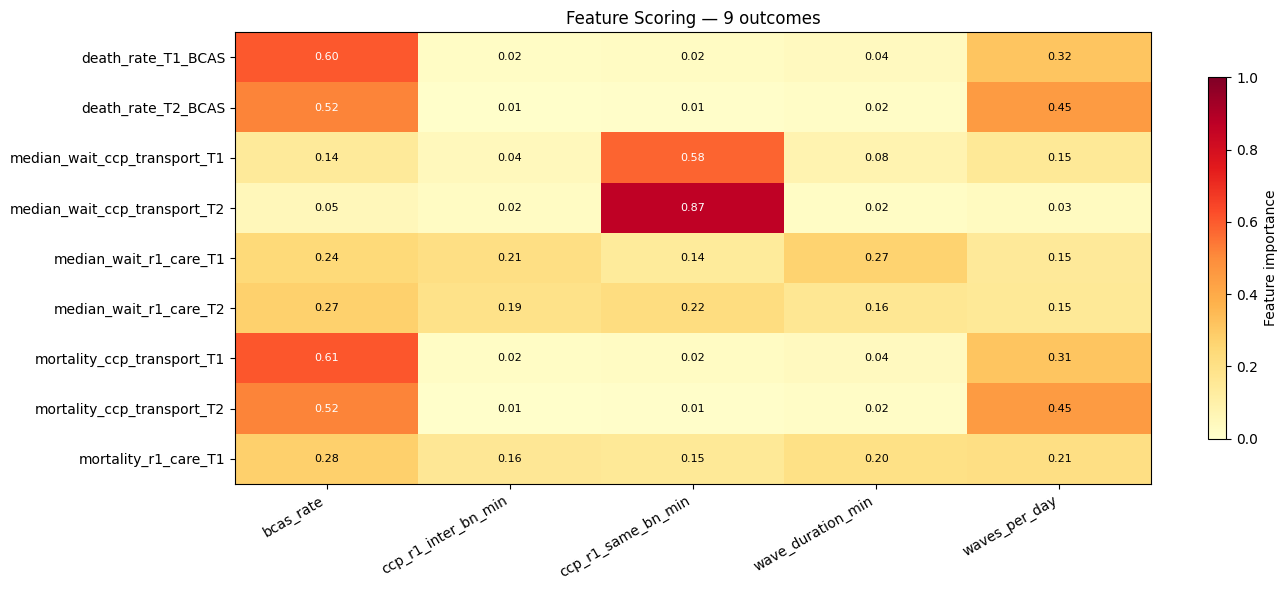

                     death_rate_T1_BCAS  death_rate_T2_BCAS  median_wait_ccp_transport_T1  median_wait_ccp_transport_T2  median_wait_r1_care_T1  median_wait_r1_care_T2  mortality_ccp_transport_T1  mortality_ccp_transport_T2  mortality_r1_care_T1
0                                                                                                                                                                                                                                                    
bcas_rate                         0.603               0.516                         0.143                         0.054                   0.241                   0.274                       0.607                       0.516                 0.281
ccp_r1_inter_bn_min               0.020               0.006                         0.044                         0.024                   0.208                   0.195                       0.020                       0.006                 0.156
ccp_r1_same_bn_m

In [2]:
scores = feature_scoring.get_feature_scores_all(x, y)
scored_uncertainties = scores.index.tolist()
scored_outcomes = scores.columns.tolist()

fig, ax = plt.subplots(figsize=(14, max(6, len(scored_outcomes) * 0.5)))
im = ax.imshow(scores.values.T, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(scored_uncertainties)))
ax.set_xticklabels(scored_uncertainties, rotation=30, ha="right")
ax.set_yticks(range(len(scored_outcomes)))
ax.set_yticklabels(scored_outcomes)
ax.set_title(f"Feature Scoring — {len(scored_outcomes)} outcomes")

for i in range(len(scored_outcomes)):
    for j in range(len(scored_uncertainties)):
        v = scores.values.T[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.5 else "black")

plt.colorbar(im, ax=ax, shrink=0.8, label="Feature importance")
plt.tight_layout()
plt.show()

print(scores.to_string(float_format="%.3f"))
